# Read MS csv from QQQ export

## import

In [1]:
import io
import warnings
import pandas as pd
import numpy as np
from pathlib import Path
# import re  # for debugging

## read csv

In [2]:
# Read the CSV file
file = "20260521.csv"
file_path = Path('../current_working_data/') / file  # this should be in the current_working_data directory
assert file_path.is_file(), f"File not found: {file_path}. Please double check that the file is in current_working_data."

with open(file_path, 'r') as f:
    lines = f.readlines()

# instrument filepath from metadata 
instrument_filepath = lines[0].strip().split(',', 1)[1]  # split on first comma only
print(f"Instrument path: {instrument_filepath}")

Instrument path: D:\MassHunter\Data\ZD\202605\20260520_TigE_activity\QuantResults\20260520_TigE_activity.batch.bin


## find sequence and data table lines in the csv

In [3]:
# find sequence and data tables by looking for "Data File" in the table header row
table_starts = []  # (name_line_index, header_line_index, table_name)
for i, line in enumerate(lines):
    if line.strip().startswith('Data File'):
        table_starts.append((i - 1, i, lines[i - 1].strip().strip(',')))  # name row is the line just before

# find table names and print for checking 
table_names = [table_name for _, _, table_name in table_starts]
print(f"Found {len(table_starts)} tables {table_names} at indices:")
max_width = max(len(name) for name in table_names) + 2
for name_idx, header_idx, table_name in table_starts:
    print(f"  {table_name:<{max_width}} : {header_idx}")

Found 4 tables ['Sequence Table', 'Methionine', '5dA', '5 MTA'] at indices:
  Sequence Table   : 4
  Methionine       : 118
  5dA              : 176
  5 MTA            : 234


## parse into dataframes and clean

In [4]:
tables = {}

# parse into however many tables 
for t, (name_idx, header_idx, name) in enumerate(table_starts):
    end_idx = table_starts[t + 1][0] if t + 1 < len(table_starts) else len(lines)  # find last line of each table 
    chunk = ''.join(lines[header_idx:end_idx])  # add the header line in 
    # debugging print statements 
    # print(f"--- {name} ---")
    # print(repr(chunk[:200]))  # show raw first 200 chars including escape characters
    # first_line = chunk.split('\n')[0]
    # print(f"{name}: {repr(first_line)}")
    # print()
    tables[name] = pd.read_csv(io.StringIO(chunk), 
                               header=0, 
                               skip_blank_lines=True,
                               na_values=['ND']
                               ).dropna(how='all')

# if any columns aren't returning the right data type 
debug = 0
if debug:
    print("debugging")
    for name, table in tables.items():
        for col in table.columns:
            if pd.api.types.is_string_dtype(table[col]) and col not in ['Data File', 'Type', 'ISTD', 'Name', 'Acq. Method File']:
                non_numeric = table[col].dropna()
                non_numeric = non_numeric[pd.to_numeric(non_numeric, errors='coerce').isna()]
                if len(non_numeric) > 0:
                    values = ', '.join(f"'{v}'" for v in non_numeric.unique())
                    print(f"{name} — '{col}': {values}")
    print("\n")

# show head of each table to check 
for name, table in tables.items():
    print(f"--- {name} (first five rows) ---")
    display(table.head())
    if debug:
        print("Confirm all table data with numbers are float64, not str. Otherwise add NA values to na_values=['ND'] in pd.read_csv() call")
        print(table.dtypes)
    print()

# ...existing code...
csv_column_names = {
    name: table.columns.tolist()
    for name, table in tables.items()
}

--- Sequence Table (first five rows) ---


,Data File,Name,Type,Vial,Vol.,Level,Acq. Method File
0,01.d,1 blank,Blank,NaN,3,NaN,ExtendC18_MRM_5dA Met 5MTA_Trp ISTD.m
1,02.d,2 blank,Blank,NaN,3,NaN,ExtendC18_MRM_5dA Met 5MTA_Trp ISTD.m
2,03.d,3 std 0,Cal,NaN,3,1.0,ExtendC18_MRM_5dA Met 5MTA_Trp ISTD.m
3,04.d,4 std 0.5,Cal,NaN,3,2.0,ExtendC18_MRM_5dA Met 5MTA_Trp ISTD.m
4,05.d,5 std 1,Cal,NaN,3,3.0,ExtendC18_MRM_5dA Met 5MTA_Trp ISTD.m



--- Methionine (first five rows) ---


,Data File,Type,ISTD,RT,Resp.,ISTD Resp,RR,Final Conc.,Exp. Conc.,Accuracy
0,01.d,Blank,Trp,1.269,5.0,3.0,1.435928,33.4347,NaN,NaN
1,02.d,Blank,Trp,1.208,17.0,3.0,6.038097,102.8388,NaN,NaN
2,03.d,Cal,Trp,1.147,33.0,23134.0,0.001418,0.1936,0.0,NaN
3,04.d,Cal,Trp,1.244,133.0,21161.0,0.006266,0.3294,0.5,65.9
4,05.d,Cal,Trp,1.232,597.0,21004.0,0.028445,0.9480,1.0,94.8



--- 5dA (first five rows) ---


,Data File,Type,ISTD,RT,Resp.,ISTD Resp,RR,Final Conc.,Exp. Conc.,Accuracy
0,01.d,Blank,Trp,2.171,1.0,3.0,0.383417,0.7167,NaN,NaN
1,02.d,Blank,Trp,2.147,11.0,3.0,4.125648,8.0064,NaN,NaN
2,03.d,Cal,Trp,2.171,53.0,23134.0,0.002279,0.0263,0.0,NaN
3,04.d,Cal,Trp,2.123,5182.0,21161.0,0.244869,0.4648,0.5,93.0
4,05.d,Cal,Trp,2.123,11756.0,21004.0,0.559699,1.0389,1.0,103.9



--- 5 MTA (first five rows) ---


,Data File,Type,ISTD,RT,Resp.,ISTD Resp,RR,Final Conc.,Exp. Conc.,Accuracy
0,01.d,Blank,Trp,3.336,48.0,3.0,15.080300,8.2317,NaN,NaN
1,02.d,Blank,Trp,3.348,62.0,3.0,22.169297,13.3099,NaN,NaN
2,03.d,Cal,Trp,3.324,160.0,23134.0,0.006928,0.0000,0.0,NaN
3,04.d,Cal,Trp,3.324,25580.0,21161.0,1.208838,0.3672,0.5,73.4
4,05.d,Cal,Trp,3.324,59052.0,21004.0,2.811478,1.1832,1.0,118.3


## rename columns and pivot

In [5]:
# Split sequence and data table names for separate processing
sequence_table_name = table_names[0]
data_table_names = table_names[1:]

# Rename columns in data tables with their table name as prefix
skip_cols = ['Type', 'ISTD']
double_rename = False
for name, table in tables.items():
    if name != sequence_table_name:
        try:
            tables[name] = table.drop(columns=skip_cols)
        except KeyError:
            double_rename = True 
            pass
if double_rename:
    print("Note: you may have doubly renamed your data tables. If you see something like \"Methionine_Methionine_RT\" \n" 
          "in your column names, run the cell \"parse into dataframes and clean\" above and then this cell again.\n")

for table_name in data_table_names:
    tables[table_name].columns = [f'{table_name}_{col}' if col != 'Data File' else 'Data File' for col in tables[table_name].columns]
# to check column renaming: 
# print("Renamed columns in data tables:")
# for table_name in data_table_names:
#     print(f"  {table_name}: {tables[table_name].columns.tolist()}")
# print()

# Merge data tables into the sequence table, matching on the 'Data File' column
final_df = tables[sequence_table_name]
for name in data_table_names:
    final_df = final_df.merge(tables[name], on='Data File', how='left')

# Remove any remaining blank rows
final_df = final_df.dropna(how='all')

# Split "3 std 0" into index 3 and Name "std 0" (matches the xlsx import)
idx_name = final_df['Name'].astype(str).str.split(n=1, expand=True)
final_df.insert(final_df.columns.get_loc('Name'), 'index', pd.to_numeric(idx_name[0], errors='coerce').astype('Int64'))
final_df['Name'] = idx_name[1]

# print("Column names:")
# print(final_df.columns.tolist())
print(f"Sequence table rows: {len(tables[sequence_table_name])}")
print(f"Data tables rows: {[len(tables[name]) for name in data_table_names]}")
print(f"Final dataframe shape (rows, cols): {final_df.shape}")
if final_df.shape[0] != len(tables[sequence_table_name]):
    print("Warning: final dataframe row count does not match sequence table row count. Check for merge issues.")
else:
    print("Row count matches sequence table row count, looks good.")
print(f"Target compounds in table: {data_table_names}")
print(f"First few rows:")
pd.set_option('display.max_columns', None)
display(final_df.head(10))
# print("Full dataframe:")
# display(final_df)

Sequence table rows: 56
Data tables rows: [56, 56, 56]
Final dataframe shape (rows, cols): (56, 29)
Row count matches sequence table row count, looks good.
Target compounds in table: ['Methionine', '5dA', '5 MTA']
First few rows:


,Data File,index,Name,Type,Vial,Vol.,Level,Acq. Method File,Methionine_RT,Methionine_Resp.,Methionine_ISTD Resp,Methionine_RR,Methionine_Final Conc.,Methionine_Exp. Conc.,Methionine_Accuracy,5dA_RT,5dA_Resp.,5dA_ISTD Resp,5dA_RR,5dA_Final Conc.,5dA_Exp. Conc.,5dA_Accuracy,5 MTA_RT,5 MTA_Resp.,5 MTA_ISTD Resp,5 MTA_RR,5 MTA_Final Conc.,5 MTA_Exp. Conc.,5 MTA_Accuracy
0,01.d,1,blank,Blank,NaN,3,NaN,ExtendC18_MRM_5dA Met 5MTA_Trp ISTD.m,1.269,5.0,3.0,1.435928,33.4347,NaN,NaN,2.171,1.0,3.0,0.383417,0.7167,NaN,NaN,3.336,48.0,3.0,15.080300,8.2317,NaN,NaN
1,02.d,2,blank,Blank,NaN,3,NaN,ExtendC18_MRM_5dA Met 5MTA_Trp ISTD.m,1.208,17.0,3.0,6.038097,102.8388,NaN,NaN,2.147,11.0,3.0,4.125648,8.0064,NaN,NaN,3.348,62.0,3.0,22.169297,13.3099,NaN,NaN
2,03.d,3,std 0,Cal,NaN,3,1.0,ExtendC18_MRM_5dA Met 5MTA_Trp ISTD.m,1.147,33.0,23134.0,0.001418,0.1936,0.00,NaN,2.171,53.0,23134.0,0.002279,0.0263,0.00,NaN,3.324,160.0,23134.0,0.006928,0.0000,0.00,NaN
3,04.d,4,std 0.5,Cal,NaN,3,2.0,ExtendC18_MRM_5dA Met 5MTA_Trp ISTD.m,1.244,133.0,21161.0,0.006266,0.3294,0.50,65.9,2.123,5182.0,21161.0,0.244869,0.4648,0.50,93.0,3.324,25580.0,21161.0,1.208838,0.3672,0.50,73.4
4,05.d,5,std 1,Cal,NaN,3,3.0,ExtendC18_MRM_5dA Met 5MTA_Trp ISTD.m,1.232,597.0,21004.0,0.028445,0.9480,1.00,94.8,2.123,11756.0,21004.0,0.559699,1.0389,1.00,103.9,3.324,59052.0,21004.0,2.811478,1.1832,1.00,118.3
5,06.d,6,std 2,Cal,NaN,3,4.0,ExtendC18_MRM_5dA Met 5MTA_Trp ISTD.m,1.232,1532.0,19362.0,0.079118,2.3435,2.00,117.2,2.135,23894.0,19362.0,1.234048,2.2888,2.00,114.4,3.324,113959.0,19362.0,5.885582,2.8055,2.00,140.3
6,07.d,7,std 3.33,Cal,NaN,3,5.0,ExtendC18_MRM_5dA Met 5MTA_Trp ISTD.m,1.232,2401.0,18750.0,0.128073,3.6693,3.33,110.2,2.098,37592.0,18750.0,2.004903,3.7533,3.33,112.7,3.324,168064.0,18750.0,8.963344,4.5152,3.33,135.6
7,08.d,8,std 5,Cal,NaN,3,6.0,ExtendC18_MRM_5dA Met 5MTA_Trp ISTD.m,1.232,3638.0,18047.0,0.201566,5.6205,5.00,112.4,2.098,54319.0,18047.0,3.009873,5.7250,5.00,114.5,3.324,214592.0,18047.0,11.890784,6.2345,5.00,124.7
8,09.d,9,std 10,Cal,NaN,3,7.0,ExtendC18_MRM_5dA Met 5MTA_Trp ISTD.m,1.232,7212.0,17318.0,0.416426,11.0826,10.00,110.8,2.111,98120.0,17318.0,5.665796,11.3413,10.00,113.4,3.324,337209.0,17318.0,19.471672,11.2509,10.00,112.5
9,10.d,10,std 20,Cal,NaN,3,8.0,ExtendC18_MRM_5dA Met 5MTA_Trp ISTD.m,1.232,15466.0,16763.0,0.922663,22.7979,20.00,114.0,2.123,175289.0,16763.0,10.457054,23.7746,20.00,118.9,3.324,542569.0,16763.0,32.367516,24.1033,20.00,120.5


# Read MS xlsx from HFX export

## choose file

In [6]:
# Read the xlsx file
file = "20261021.xlsx"
file_path = Path('../current_working_data/') / file  # this should be in the current_working_data directory
assert file_path.is_file(), f"File not found: {file_path}. Please double check that the file is in current_working_data."

## parse xlsx file

In [7]:
# Parse each worksheet of the HFX export into the same layout as the QQQ csv import above:
#   sequence table: Data File, Name, Type, Level
#   compound tables: Data File, RT, Resp., ISTD Resp, RR, Final Conc., Exp. Conc., Accuracy
# so final_df has the same columns (e.g. "Met_RR", "Met_Final Conc.") as the csv path.
# The instrument export has page header/footer print settings openpyxl can't parse. They're irrelevant to the data, so silence only that warning.
warnings.filterwarnings("ignore", message="Cannot parse header or footer", category=UserWarning, module="openpyxl")
excel_file = pd.ExcelFile(file_path, engine="openpyxl")

header_idx = 4  # Row 5 in Excel (zero-based index)

# HFX column -> QQQ column
sequence_columns = {"Filename": "Data File", "Sample Type": "Type", "Level": "Level"}
compound_columns = {
    "Filename": "Data File",
    "RT": "RT",
    "Area": "Resp.",
    "ISTD Area": "ISTD Resp",
    "Response Ratio": "RR",
    "Calc Amt": "Final Conc.",
    "Exp Amt": "Exp. Conc.",
    "%Diff": "Accuracy",
}
type_map = {"Unknown Sample": "Sample", "Std Bracket Sample": "Cal", "Blank Sample": "Blank"}
text_columns = ["Data File", "Name", "Type"]

raw_tables = {}
for sheet_name in excel_file.sheet_names:
    raw = pd.read_excel(excel_file, sheet_name=sheet_name, header=None, dtype=object)
    if len(raw) <= header_idx:
        continue

    # Ignore trailing workbook metadata ("Created By:").
    end_idx = len(raw)
    for row_idx in range(header_idx + 1, len(raw)):
        if any(isinstance(v, str) and v.strip().casefold().startswith("created by")
               for v in raw.iloc[row_idx].tolist()):
            end_idx = row_idx
            break

    table = raw.iloc[header_idx + 1:end_idx].copy()
    table.columns = [str(v).strip() if pd.notna(v) else "" for v in raw.iloc[header_idx]]
    table = table.loc[:, table.columns != ""]
    if "Filename" in table.columns:
        table = table[table["Filename"].astype(str).str.strip().ne("") & table["Filename"].notna()]
    else:
        table = table.iloc[0:0]
    if table.empty:  # e.g. the empty "Component" sheet
        print(f"Skipping sheet with no data rows: {sheet_name}")
        continue
    raw_tables[sheet_name] = table.reset_index(drop=True)

if not raw_tables:
    raise ValueError("No worksheets with data below the row 5 header were found.")

# Sequence table: file info is identical on every sheet, so take it from the first one.
data_table_names = list(raw_tables)
sequence_table_name = "Sequence Table"
first = raw_tables[data_table_names[0]]
seq = first[[c for c in sequence_columns if c in first.columns]].rename(columns=sequence_columns)
seq["Type"] = seq["Type"].map(type_map).fillna(seq["Type"])
# "41-noSAM-30" -> index 41, Name "noSAM 30"
idx_name = seq["Data File"].astype(str).str.split("-", n=1, expand=True)
seq["index"] = pd.to_numeric(idx_name[0], errors="coerce").astype("Int64")
seq["Name"] = idx_name[1].fillna("").str.replace("-", " ")
seq = seq[["Data File", "index", "Name", "Type"] + [c for c in seq.columns if c not in ("Data File", "index", "Name", "Type")]]

tables = {sequence_table_name: seq}
for name, table in raw_tables.items():
    table = table[[c for c in compound_columns if c in table.columns]].rename(columns=compound_columns)
    # Non-numeric entries like "-1.#IND00000000000" or "ND" become NaN
    for col in table.columns.difference(text_columns):
        table[col] = pd.to_numeric(table[col], errors="coerce")
    tables[name] = table

table_names = [sequence_table_name] + data_table_names

# Prefix compound columns with the compound name and merge into the sequence table
final_df = tables[sequence_table_name].copy()
for name in data_table_names:
    data_table = tables[name].copy()
    data_table.columns = [c if c == "Data File" else f"{name}_{c}" for c in data_table.columns]
    final_df = final_df.merge(data_table, on="Data File", how="left")
final_df = final_df.dropna(how="all")

print(f"Sequence table rows: {len(tables[sequence_table_name])}")
print(f"Final dataframe shape (rows, cols): {final_df.shape}")
if final_df.shape[0] != len(tables[sequence_table_name]):
    print("Warning: final dataframe row count does not match sequence table row count. Check for merge issues.")
print(f"Target compounds in table: {data_table_names}")
display(final_df.head(10))

Skipping sheet with no data rows: Component
Sequence table rows: 79
Final dataframe shape (rows, cols): (79, 96)
Target compounds in table: ['SAM', 'Met', 'Ile', 'Ile_mCPG', '5_dAH', 'MTA', 'Trp', 'TigB1RmCPG_1+', 'TigB1RmCPG_2+', 'TigB1R_1+', 'TigB1R_2+', 'TigB1R-S_1+', 'TigB1R-S_2+']


,Data File,index,Name,Type,Level,SAM_RT,SAM_Resp.,SAM_ISTD Resp,SAM_RR,SAM_Final Conc.,SAM_Exp. Conc.,SAM_Accuracy,Met_RT,Met_Resp.,Met_ISTD Resp,Met_RR,Met_Final Conc.,Met_Exp. Conc.,Met_Accuracy,Ile_RT,Ile_Resp.,Ile_ISTD Resp,Ile_RR,Ile_Final Conc.,Ile_Exp. Conc.,Ile_Accuracy,Ile_mCPG_RT,Ile_mCPG_Resp.,Ile_mCPG_ISTD Resp,Ile_mCPG_RR,Ile_mCPG_Final Conc.,Ile_mCPG_Exp. Conc.,Ile_mCPG_Accuracy,5_dAH_RT,5_dAH_Resp.,5_dAH_ISTD Resp,5_dAH_RR,5_dAH_Final Conc.,5_dAH_Exp. Conc.,5_dAH_Accuracy,MTA_RT,MTA_Resp.,MTA_ISTD Resp,MTA_RR,MTA_Final Conc.,MTA_Exp. Conc.,MTA_Accuracy,Trp_RT,Trp_Resp.,Trp_ISTD Resp,Trp_RR,Trp_Final Conc.,Trp_Exp. Conc.,Trp_Accuracy,TigB1RmCPG_1+_RT,TigB1RmCPG_1+_Resp.,TigB1RmCPG_1+_ISTD Resp,TigB1RmCPG_1+_RR,TigB1RmCPG_1+_Final Conc.,TigB1RmCPG_1+_Exp. Conc.,TigB1RmCPG_1+_Accuracy,TigB1RmCPG_2+_RT,TigB1RmCPG_2+_Resp.,TigB1RmCPG_2+_ISTD Resp,TigB1RmCPG_2+_RR,TigB1RmCPG_2+_Final Conc.,TigB1RmCPG_2+_Exp. Conc.,TigB1RmCPG_2+_Accuracy,TigB1R_1+_RT,TigB1R_1+_Resp.,TigB1R_1+_ISTD Resp,TigB1R_1+_RR,TigB1R_1+_Final Conc.,TigB1R_1+_Exp. Conc.,TigB1R_1+_Accuracy,TigB1R_2+_RT,TigB1R_2+_Resp.,TigB1R_2+_ISTD Resp,TigB1R_2+_RR,TigB1R_2+_Final Conc.,TigB1R_2+_Exp. Conc.,TigB1R_2+_Accuracy,TigB1R-S_1+_RT,TigB1R-S_1+_Resp.,TigB1R-S_1+_ISTD Resp,TigB1R-S_1+_RR,TigB1R-S_1+_Final Conc.,TigB1R-S_1+_Exp. Conc.,TigB1R-S_1+_Accuracy,TigB1R-S_2+_RT,TigB1R-S_2+_Resp.,TigB1R-S_2+_ISTD Resp,TigB1R-S_2+_RR,TigB1R-S_2+_Final Conc.,TigB1R-S_2+_Exp. Conc.,TigB1R-S_2+_Accuracy
0,03-std-1,3,std 1,Cal,1,0.398008,3.185748e+06,7.111557e+07,0.044797,NaN,0.0,NaN,0.854846,4.449424e+06,7.111557e+07,0.062566,5.206469,0.000001,5.206468e+06,0.859874,1.381255e+07,7.111557e+07,0.194227,NaN,0.000001,-1.0,0.844719,5.655622e+06,7.111557e+07,0.079527,NaN,0.000001,-1.0,1.615552,7.699377e+05,7.111557e+07,0.010827,-0.415003,0.00,NaN,2.622479,2.124980e+06,7.111557e+07,0.029881,-0.772339,0.000001,-772340.018472,2.637750,7.111557e+07,NaN,NaN,NaN,5.0,NaN,NaN,NaN,7.111557e+07,NaN,NaN,0.0,NaN,3.124449,221758.012637,7.111557e+07,0.003118,NaN,0.0,NaN,NaN,NaN,7.111557e+07,NaN,NaN,0.0,NaN,NaN,NaN,7.111557e+07,NaN,NaN,0.0,NaN,NaN,NaN,7.111557e+07,NaN,NaN,0.0,NaN,3.066368,206742.568340,7.111557e+07,0.002907,0.000003,0.000001,2.319222
1,04-std-2,4,std 2,Cal,2,0.400876,2.498999e+06,7.812431e+07,0.031987,NaN,0.0,NaN,0.797963,5.889461e+06,7.812431e+07,0.075386,6.160217,0.500000,1.132043e+01,0.858779,2.090918e+07,7.812431e+07,0.267640,NaN,0.000001,-1.0,0.777904,1.728444e+06,7.812431e+07,0.022124,NaN,0.000001,-1.0,1.608652,4.204134e+07,7.812431e+07,0.538134,0.458702,0.50,-0.082596,2.622731,4.189070e+07,7.812431e+07,0.536206,0.022248,0.500000,-0.955504,2.637998,7.812431e+07,NaN,NaN,NaN,5.0,NaN,NaN,NaN,7.812431e+07,NaN,NaN,0.0,NaN,3.127154,232982.464824,7.812431e+07,0.002982,NaN,0.0,NaN,NaN,NaN,7.812431e+07,NaN,NaN,0.0,NaN,3.137652,27618.983255,7.812431e+07,0.000354,NaN,0.0,NaN,NaN,NaN,7.812431e+07,NaN,NaN,0.0,NaN,3.085340,192591.967877,7.812431e+07,0.002465,0.000002,0.000000,NaN
2,05-std-3,5,std 3,Cal,3,0.398593,2.532096e+06,7.554548e+07,0.033518,NaN,0.0,NaN,0.775236,8.729791e+06,7.554548e+07,0.115557,8.955215,1.000000,7.955215e+00,0.861211,3.656226e+07,7.554548e+07,0.483977,NaN,0.000001,-1.0,0.800308,5.487419e+06,7.554548e+07,0.072637,NaN,0.000001,-1.0,1.587208,8.339366e+07,7.554548e+07,1.103887,1.410769,1.00,0.410769,2.621715,1.032448e+08,7.554548e+07,1.366658,1.341668,1.000000,0.341668,2.636991,7.554548e+07,NaN,NaN,NaN,5.0,NaN,NaN,NaN,7.554548e+07,NaN,NaN,0.0,NaN,3.123873,156824.238975,7.554548e+07,0.002076,NaN,0.0,NaN,NaN,NaN,7.554548e+07,NaN,NaN,0.0,NaN,3.071395,15265.254127,7.554548e+07,0.000202,NaN,0.0,NaN,NaN,NaN,7.554548e+07,NaN,NaN,0.0,NaN,3.071395,208655.278351,7.554548e+07,0.002762,0.000003,0.000000,NaN
3,06-std-4,6,std 4,Cal,4,0.405849,2.291488e+06,8.135403e+07,0.028167,NaN,0.0,NaN,0.653295,3.186870e+06,8.135403e+07,0.039173,3.371518,3.330000,1.246778e-02,0.868218,9.639713e+07,8.135403e+07,1.184909,NaN,0.000001,-1.0,0.960204,3.686296e+06,8.135403e+07,0.045312,NaN,0.0000

# Plot data

## import

In [27]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

from pathlib import Path
from matplotlib import font_manager as fm

for f in Path("../fonts").glob("texgyrepagella-*.otf"): 
    fm.fontManager.addfont(str(f))

plt.rcParams.update({
    "font.family": "TeX Gyre Pagella",
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
})
print(fm.findfont(fm.FontProperties(family="TeX Gyre Pagella", weight="bold")))  # should end in ...bold.otf

/Users/zachdinardo/Desktop/School/Penn/BookerLab/BookerLabZD-code/fonts/texgyrepagella-bold.otf


## Standard curves

## Data

### set plot title, legend, and colors

Current plot titles:
20261021 process_20261015 TigE activity assay_{compound}_{RR or conc}.png
Change "assay_title" in cell above to update

copy+paste dictionaries into cell below and edit

label_map_dict = {
    'TigB1R': 'TigB1R',
    'ile': 'ile',
    'lowSAM': 'lowSAM',
    'noEnz': 'noEnz',
    'noSAM': 'noSAM',
    'noSub': 'noSub',
    'noTi': 'noTi',
}

legend_order = [
    'TigB1R',
    'ile',
    'lowSAM',
    'noEnz',
    'noSAM',
    'noSub',
    'noTi',
]

Colormap: tab10
color_map_dict = {
    'TigB1R': '#1f77b4',
    'ile': '#ff7f0e',
    'lowSAM': '#2ca02c',
    'noEnz': '#d62728',
    'noSAM': '#9467bd',
    'noSub': '#8c564b',
    'noTi': '#e377c2',
}


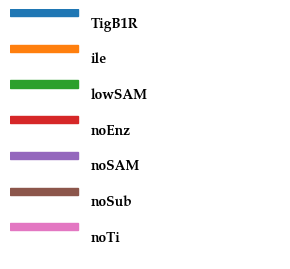

Colormap: Set1
color_map_dict = {
    'TigB1R': '#e41a1c',
    'ile': '#377eb8',
    'lowSAM': '#4daf4a',
    'noEnz': '#984ea3',
    'noSAM': '#ff7f00',
    'noSub': '#ffff33',
    'noTi': '#a65628',
}


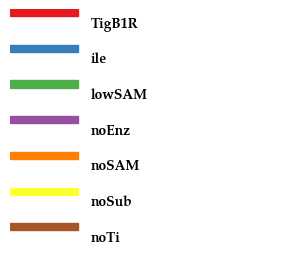

Colormap: Set2
color_map_dict = {
    'TigB1R': '#66c2a5',
    'ile': '#fc8d62',
    'lowSAM': '#8da0cb',
    'noEnz': '#e78ac3',
    'noSAM': '#a6d854',
    'noSub': '#ffd92f',
    'noTi': '#e5c494',
}


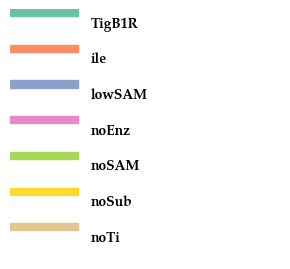

Colormap: Paired
color_map_dict = {
    'TigB1R': '#a6cee3',
    'ile': '#1f78b4',
    'lowSAM': '#b2df8a',
    'noEnz': '#33a02c',
    'noSAM': '#fb9a99',
    'noSub': '#e31a1c',
    'noTi': '#fdbf6f',
}


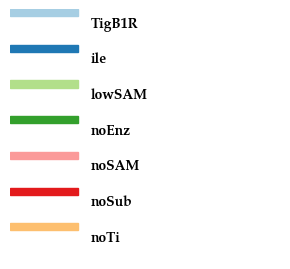

In [32]:
# Filter data for samples (not blanks or calibration standards)
samples_df = final_df[(final_df['Type'] == 'Sample') & (~final_df['Name'].str.contains('water', case=False, na=False))].copy()

# Parse the Name column to extract condition and time (index is already a column from the import)
samples_df[['condition', 'time']] = samples_df['Name'].str.split(expand=True, n=1)
conditions = sorted(samples_df['condition'].dropna().unique())
samples_df['time'] = pd.to_numeric(samples_df['time'], errors='coerce')

# set name for figures
assay_title = "20261015 TigE activity assay"
sample_out_png = str(file_path).split('.')[-2].split('/')[-1] + " process_" + assay_title + '_{compound}_{RR or conc}.png'
print(f"Current plot titles:\n{sample_out_png}\nChange \"assay_title\" in cell above to update\n")

# figure sizing and layout (all fractions are of the whole figure, so every plot is laid out identically)
figsize = (10, 6)  # total figure size in inches (width, height)
plot_area = [0.08, 0.10, 0.62, 0.80]  # main axes: [left, bottom, width, height]
legend_anchor = (0.73, 0.90)  # top-left corner of the legend, to the right of the plot
assay_table_area = [0.73, 0.25, 0.28]  # assay info box: [left, width, height] (vertical position is set by assay_gap)
assay_gap = 0.10  # gap between the bottom of the legend and the top of the assay info box (fraction of figure height)
assay_font_size = 9  # assay info table body font size
assay_header_font_size = 11  # assay info table header font size

# assay information box: one (Reagent, Conc (mM)) row per reagent; add/remove rows as needed
assay_info = [
    ('HEPES', '50'),
    ('KCl', '300'),
    ('DTT', '10'),
    ('Ti cit', '1'),
    ('substrate', '0.100'),
    ('enzyme', '0.025'),
    ('SAM', '0.200'),
    ('low SAM', '0.050'),
]

print("copy+paste dictionaries into cell below and edit\n")
print("label_map_dict = {")
for cond in conditions:
    print(f"    '{cond}': '{cond}',")
print("}")
print()
print("legend_order = [")
for cond in conditions:
    print(f"    '{cond}',")
print("]")
print()

possible_colormaps = ['tab10', 'Set1', 'Set2', 'Paired']  # consider tab10, Set1, Set2, Paired
# Display swatches and copyable dict
for color in possible_colormaps:
    cmap = plt.colormaps[color] 
    color_map_dict = {cond: mcolors.to_hex(cmap(i)) for i, cond in enumerate(conditions)}
    print(f"Colormap: {color}")
    print("color_map_dict = {")  # print copyable dict
    for cond, hex_color in color_map_dict.items():
        print(f"    '{cond}': '{hex_color}',")
    print("}")
    color_map_dict = {cond: mcolors.to_hex(cmap(i)) for i, cond in enumerate(conditions)}
    fig, ax = plt.subplots(figsize=(3, len(conditions) * 0.4))
    for i, (cond, hex_color) in enumerate(color_map_dict.items()):
        ax.add_patch(mpatches.Rectangle((0, i), 1, 0.2, color=hex_color))
        ax.text(1.2, i + 0.4, cond, va='center')
    ax.set_xlim(0, 4)
    ax.set_ylim(0, len(conditions))
    ax.axis('off')
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()

### plot and optionally save

Skipping concentration plot for SAM: no concentration data


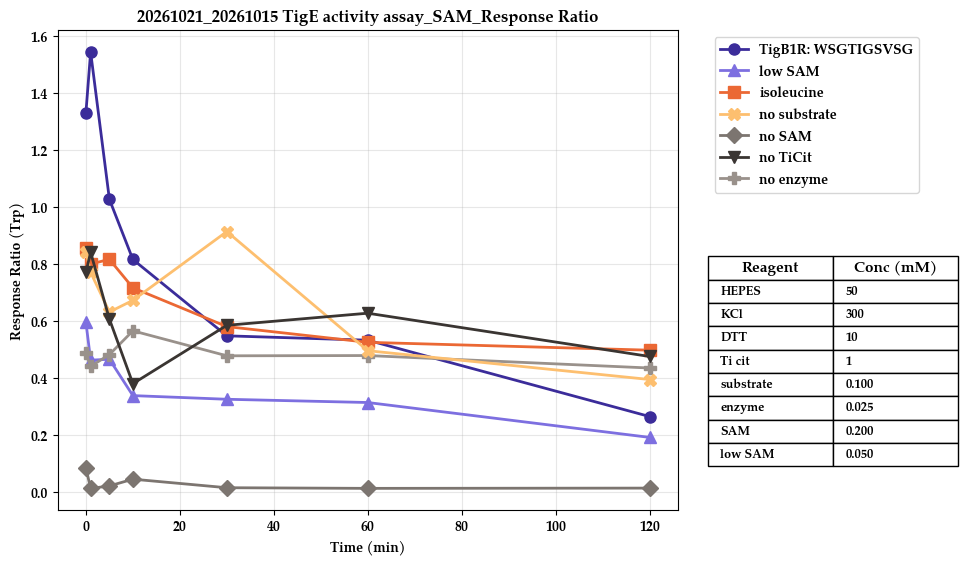

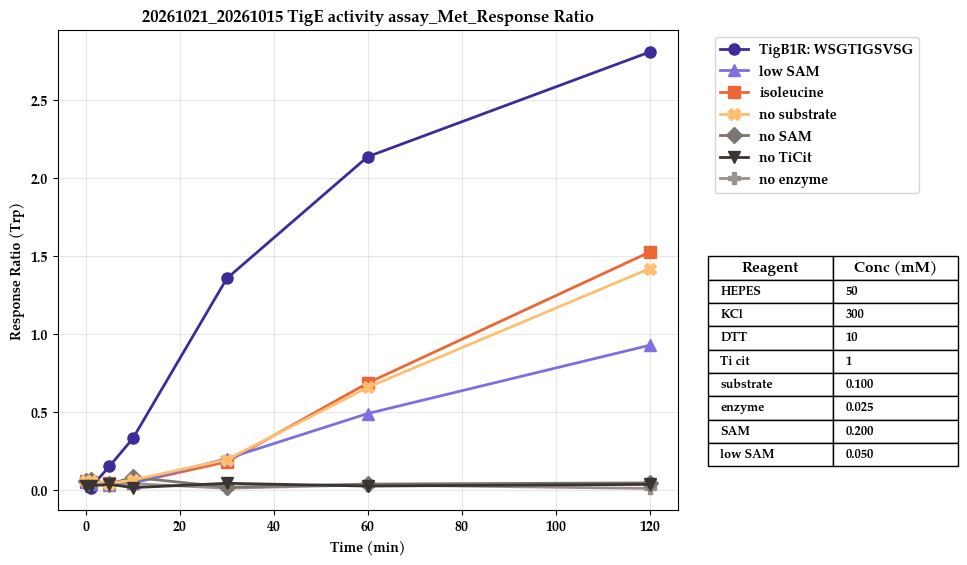

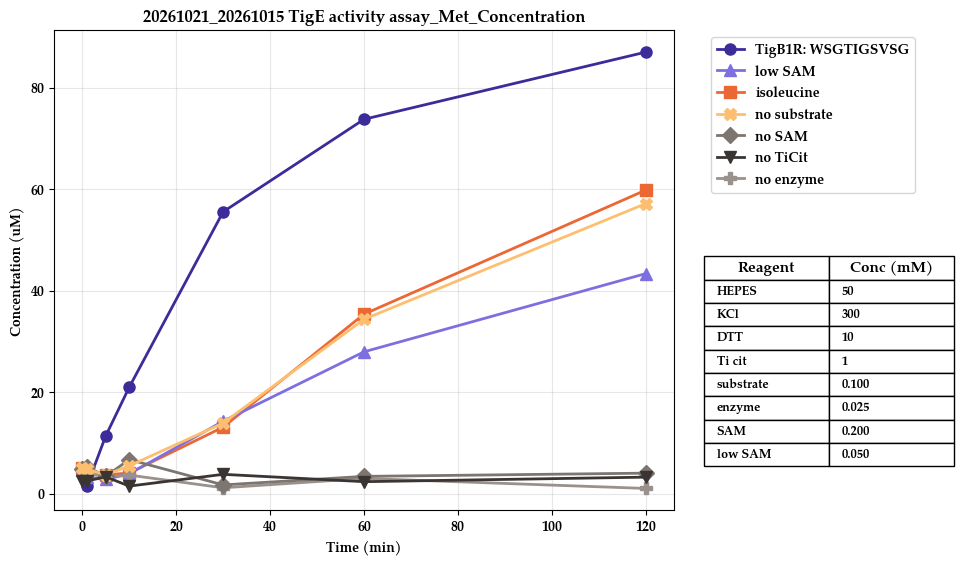

Skipping concentration plot for Ile: no concentration data


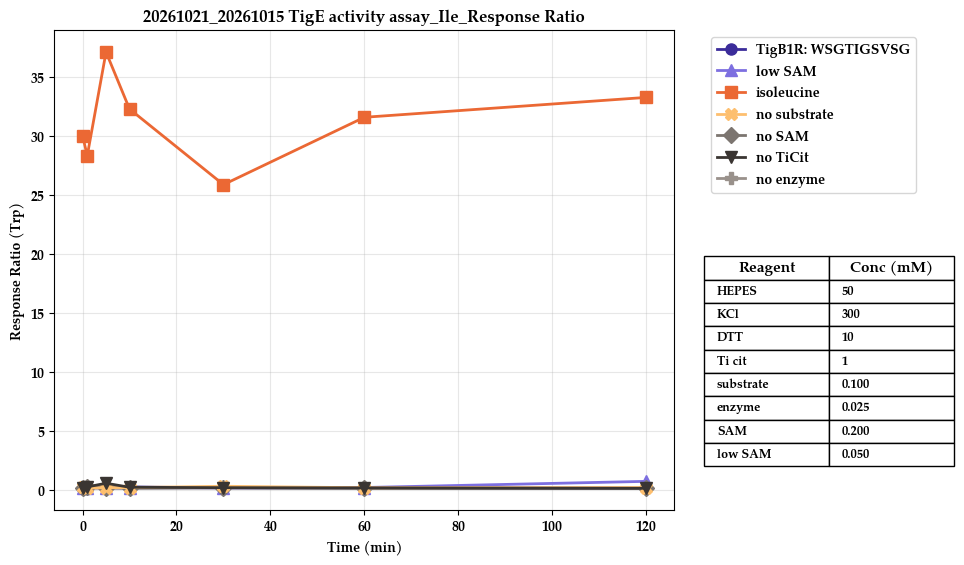

Skipping concentration plot for Ile_mCPG: no concentration data


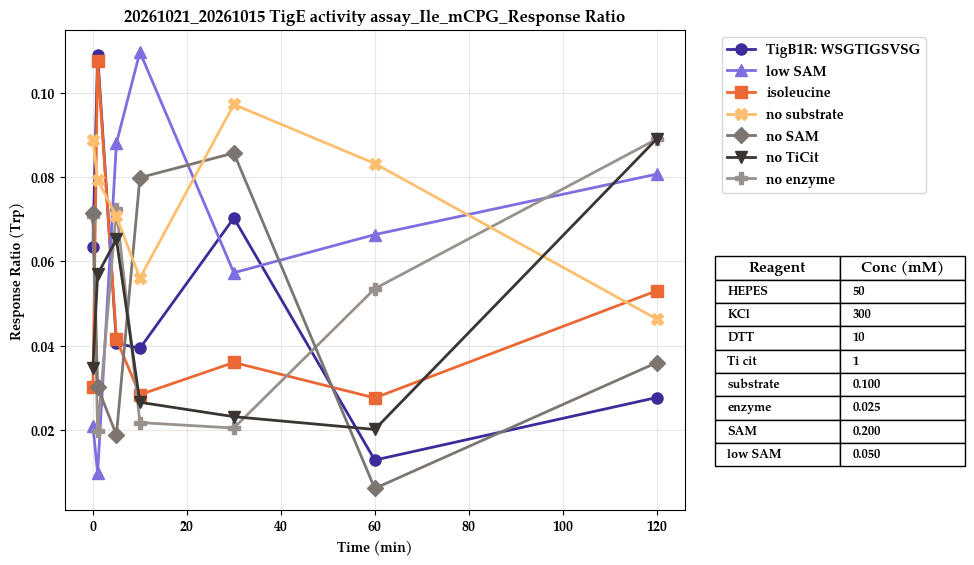

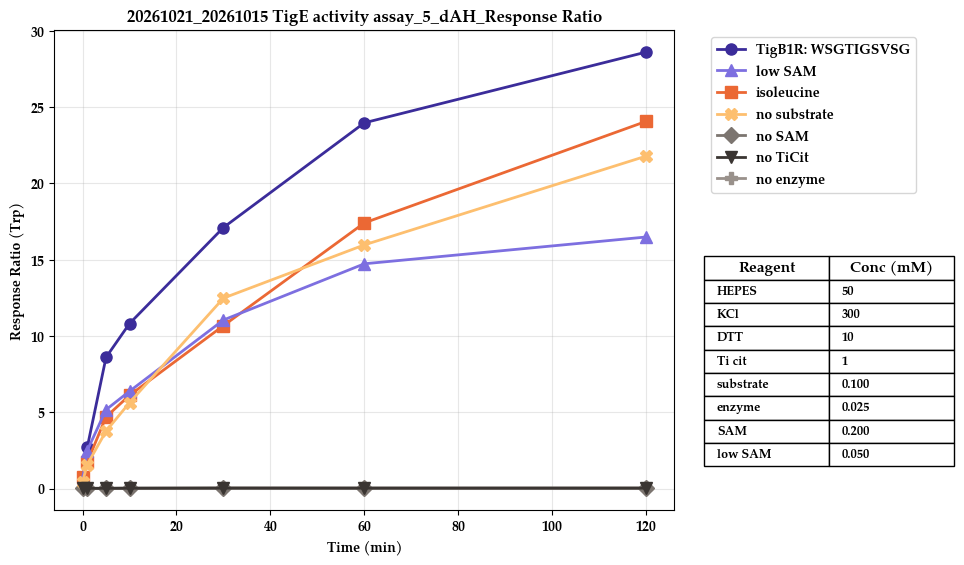

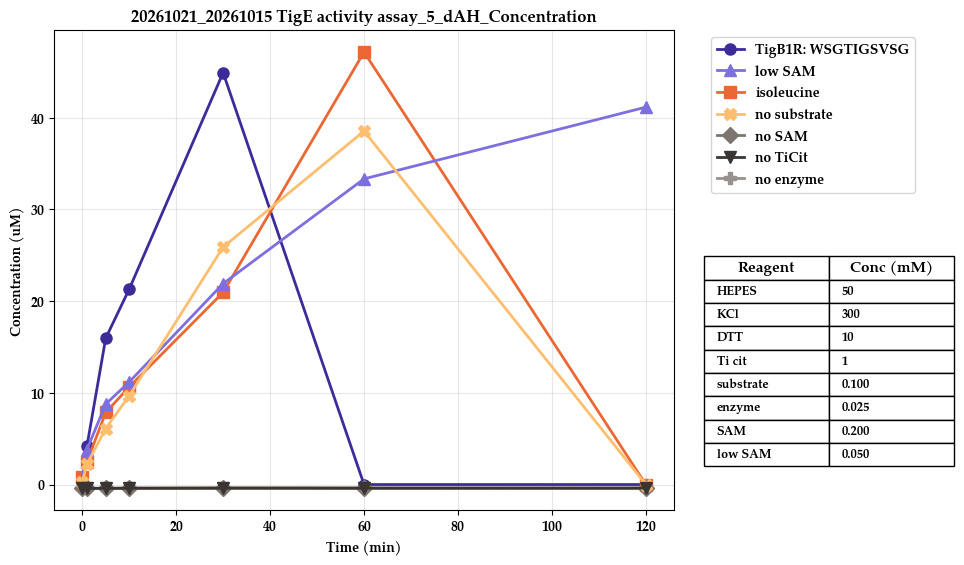

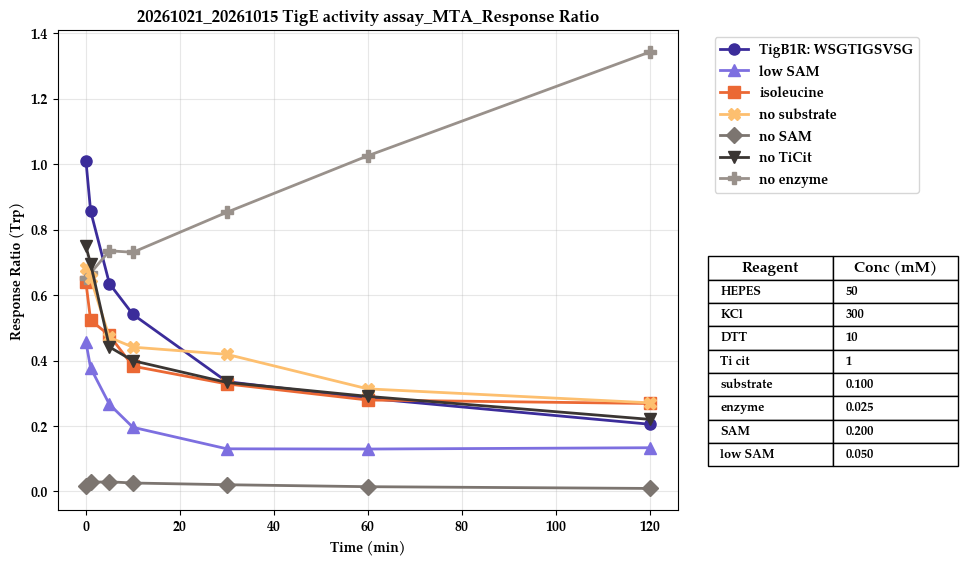

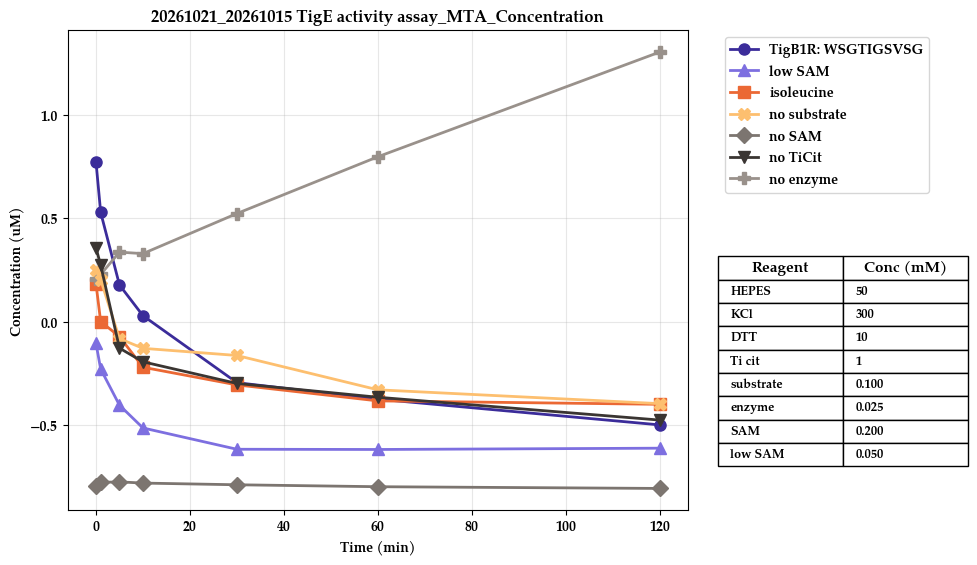

Skipping concentration plot for Trp: no concentration data


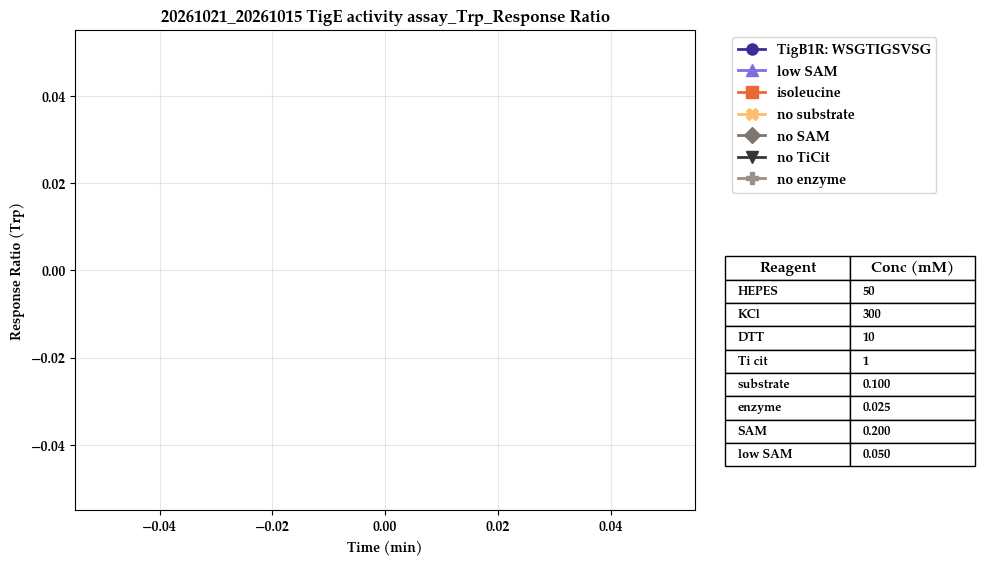

Skipping concentration plot for TigB1RmCPG_1+: no concentration data


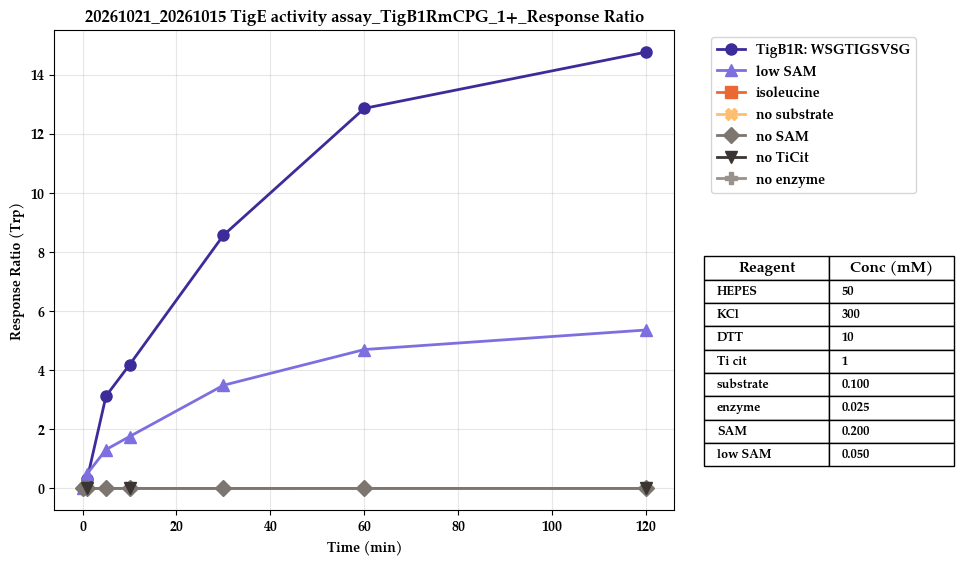

Skipping concentration plot for TigB1RmCPG_2+: no concentration data


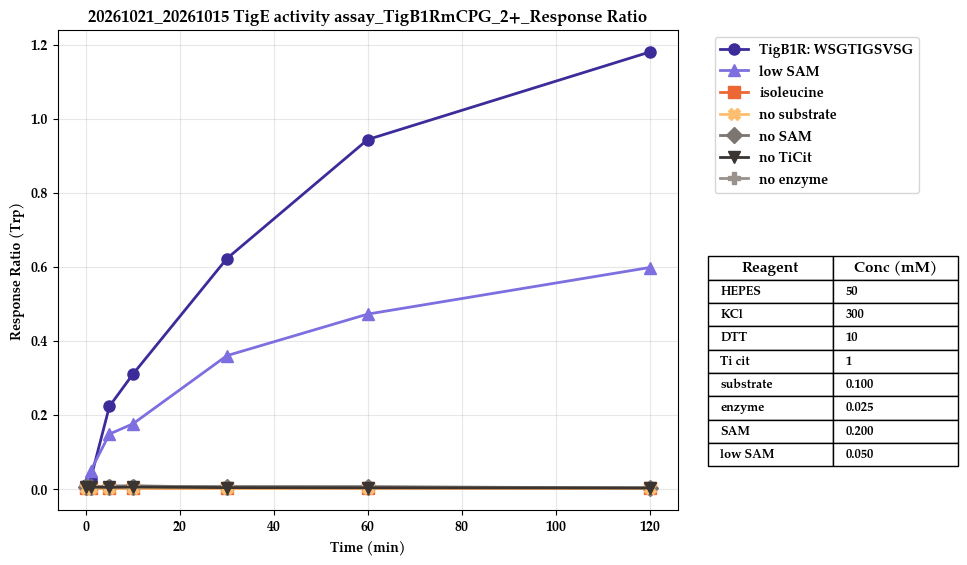

Skipping concentration plot for TigB1R_1+: no concentration data


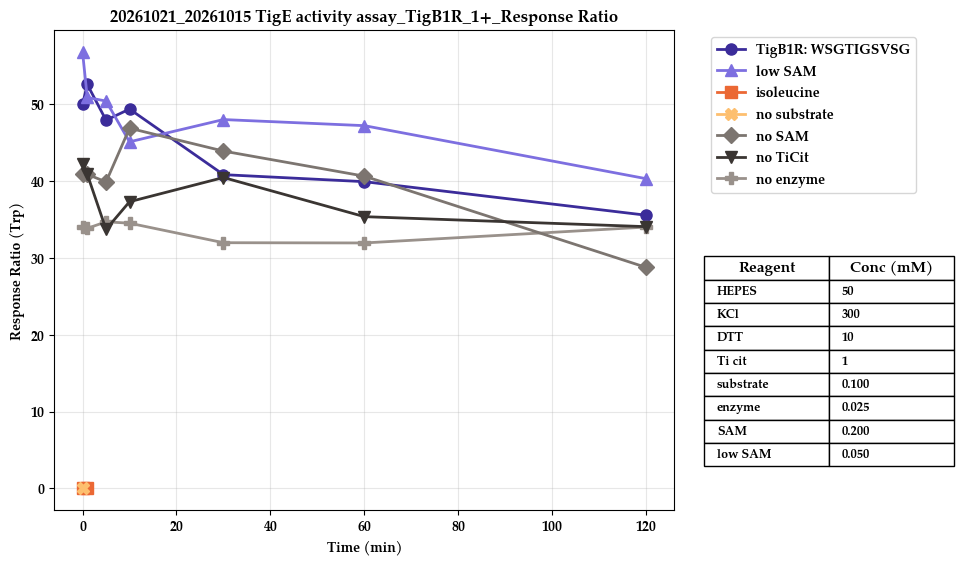

Skipping concentration plot for TigB1R_2+: no concentration data


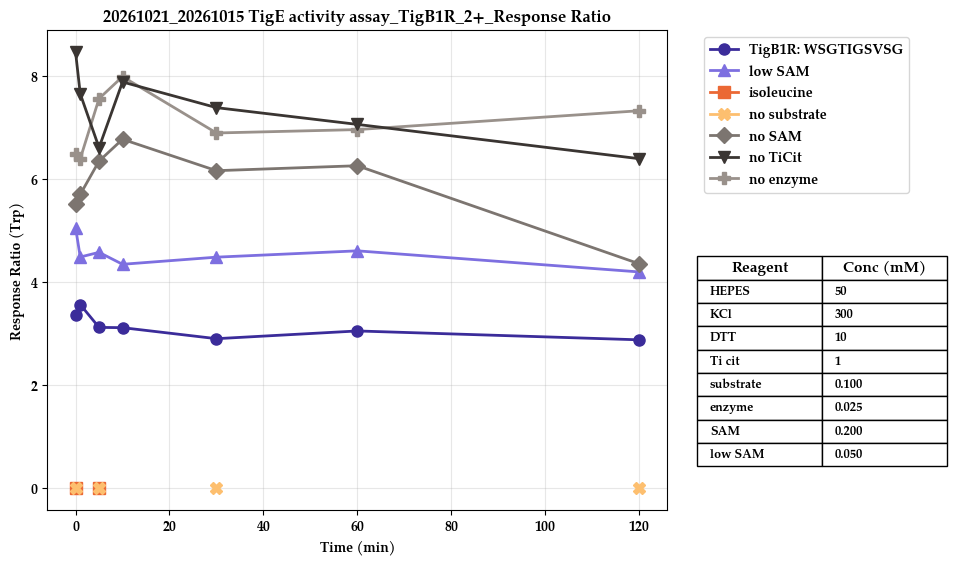

Skipping concentration plot for TigB1R-S_1+: no concentration data


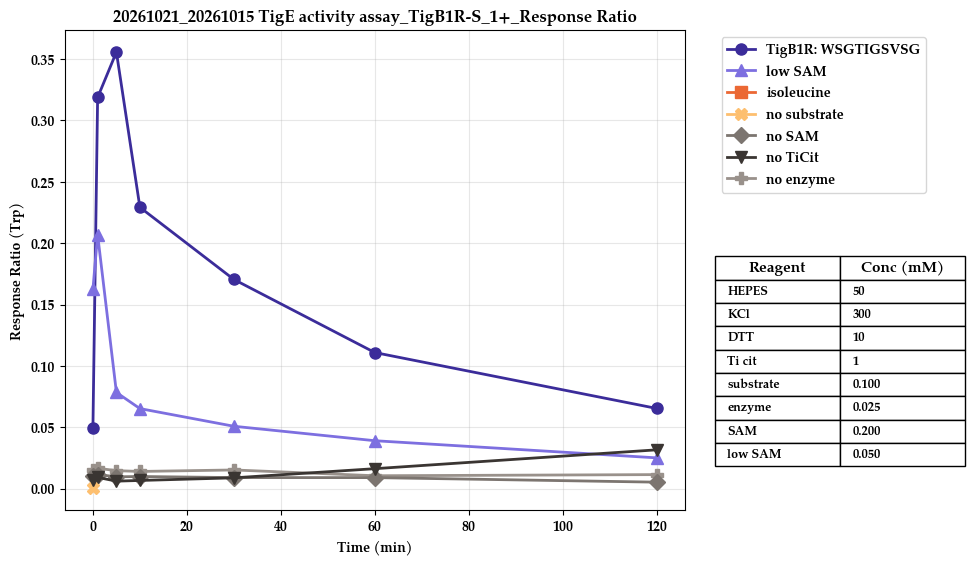

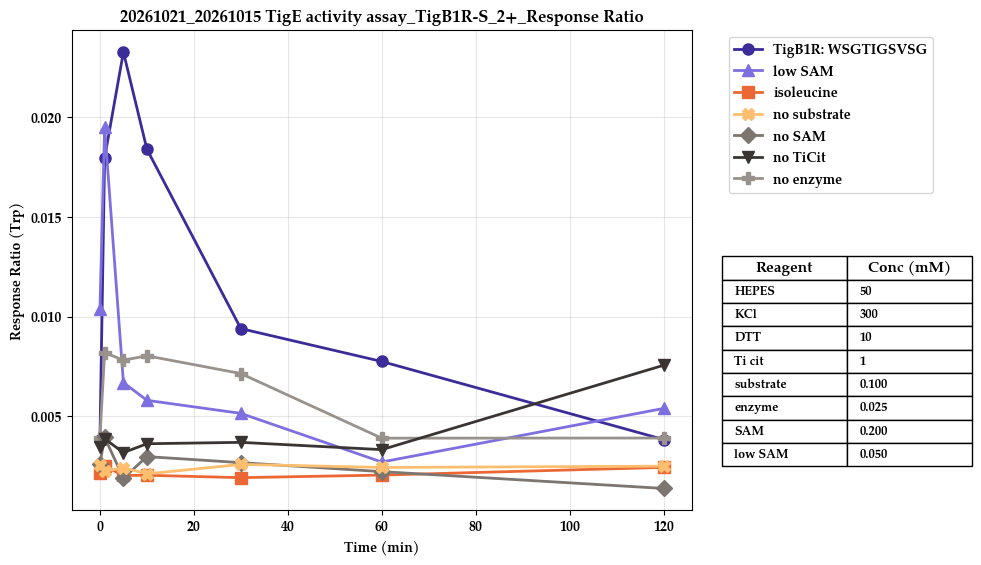

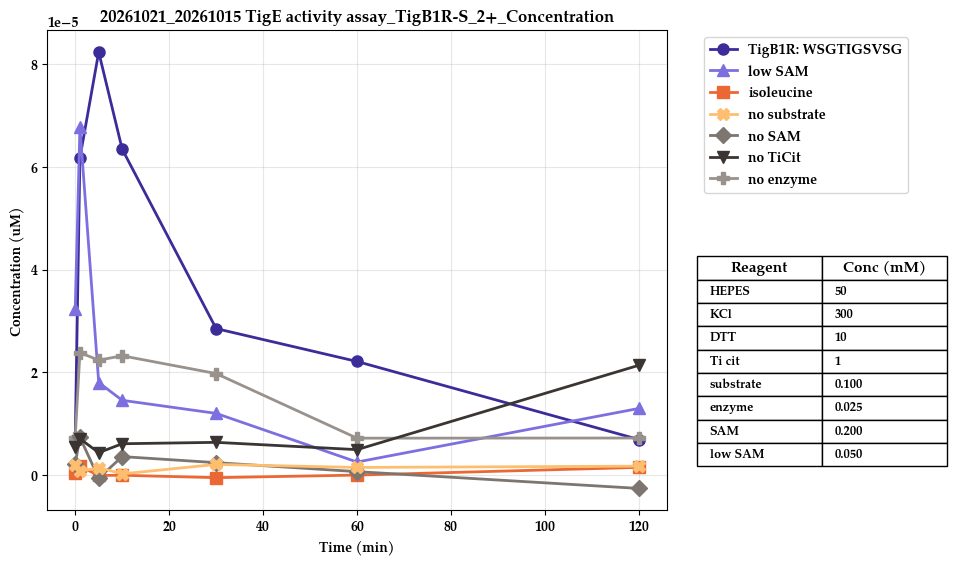

In [35]:
save_plots = 1  # set to True once you're ready to save output pngs
plot_RR = 1 
plot_conc = 1

label_map_dict = {
    'TigB1R': 'TigB1R: WSGTIGSVSG',
    'ile': 'isoleucine',
    'lowSAM': 'low SAM',
    'noEnz': 'no enzyme',
    'noSAM': 'no SAM',
    'noSub': 'no substrate',
    'noTi': 'no TiCit',
}

# order of conditions in the legend, top to bottom (conditions left out are added at the end)
legend_order = [
    'TigB1R',
    'lowSAM',
    'ile',
    'noSub',
    'noSAM',
    'noTi',
    'noEnz',
]

color_map_dict = {
    'TigB1R': '#3b2c9a',
    'ile': '#eb6834',
    'lowSAM': '#7d6fe0',
    'noEnz': '#99918b',
    'noSAM': '#7c7570',
    'noSub': '#fdbf6f',
    'noTi': '#3a3532',
}

# o circle, s square, ^ triangle_up, P plus_filled, D diamond, X x_filled, v triangle_down, d thin diamond, * star, h hexagon 
markers = ['o', 's', '^', 'P', 'D', 'X', 'v']  # in the same order as conditions 
marker_dict = {cond: markers[i % len(markers)] for i, cond in enumerate(conditions)}

# Create plots for each compound
for compound in data_table_names:
    rr_col = f'{compound}_RR'
    conc_col = f'{compound}_Final Conc.'
    
    plots = []
    if plot_RR:
        plots.append((rr_col, 'Response Ratio'))
    if plot_conc:
        # skip compounds with no concentration data (no calibration, so Final Conc. is missing or all NaN)
        if conc_col in samples_df.columns and samples_df[conc_col].notna().any():
            plots.append((conc_col, 'Concentration'))
        else:
            print(f"Skipping concentration plot for {compound}: no concentration data")

    for col, ylabel in plots:
        fig = plt.figure(figsize=figsize)
        ax = fig.add_axes(plot_area)
        for condition in conditions:
            condition_data = samples_df[samples_df['condition'] == condition].sort_values('time')
            ax.plot(
                condition_data['time'],
                condition_data[col],
                marker=marker_dict[condition],
                color=color_map_dict[condition],
                label=label_map_dict[condition],
                linewidth=2,
                markersize=8
            )
        title = f"{file_path.stem}_{assay_title}_{compound}_{ylabel}"
        ax.set_xlabel('Time (min)')
        if "response".lower() in ylabel.lower():
            ax.set_ylabel("Response Ratio (Trp)")
        elif "conc".lower() in ylabel.lower():
            ax.set_ylabel("Concentration (uM)")
        ax.set_title(title)
        ax.grid(True, alpha=0.3)

        # legend to the right of the plot, fixed position
        handle_by_cond = dict(zip(conditions, ax.get_legend_handles_labels()[0]))
        ordered_conds = [c for c in legend_order if c in handle_by_cond] + [c for c in conditions if c not in legend_order]
        handles = [handle_by_cond[c] for c in ordered_conds]
        labels = [label_map_dict[c] for c in ordered_conds]
        legend = fig.legend(handles, labels, loc='upper left', bbox_to_anchor=legend_anchor, frameon=True)

        # assay information box, its top sits assay_gap below the bottom of the legend
        fig.canvas.draw()  # needed so the legend's rendered size is known
        legend_bottom = legend.get_window_extent().transformed(fig.transFigure.inverted()).y0
        table_left, table_width, table_height = assay_table_area
        table_ax = fig.add_axes([table_left, legend_bottom - assay_gap - table_height, table_width, table_height])
        table_ax.axis('off')
        if assay_info:
            assay_table = table_ax.table(
                cellText=[list(row) for row in assay_info],
                colLabels=['Reagent', 'Conc (mM)'],
                loc='upper center',
                cellLoc='left',
            )
            assay_table.auto_set_font_size(False)
            assay_table.set_fontsize(assay_font_size)
            assay_table.scale(1, 1.4)
            for c in range(2):
                assay_table[0, c].set_text_props(fontsize=assay_header_font_size)

        # print(title)
        if save_plots:
            fig.savefig(f"{title}.png", dpi=400)
        plt.show()